# Feeding Frenzy — current-paper analysis through 36 gannets

**Entry point:** open `main.ipynb` from the repository root, restart the kernel, and choose **Run All Cells**.

Default execution verifies the frozen input hashes, reconstructs individual returns and paired changes, checks the original interval table, rebuilds the four report figures and exports the numerical summaries under `outputs/`. It checks the original eight-school timestep comparison and the departure/launch-gap diagnostics. **No model runs, native FishSim imports or new bootstrap draws occur.**

The scope is the current paper's completed four-school **1/3/6/9/12/18/24/36-gannet** bank and the separate eight-school numerical check. The upper counts now have all four schools, rather than the earlier one-school pilot. The detailed departure analysis remains explicitly restricted to the **older 48 bird-bearing encounters at 1/3/6 birds**. A newer mutable repository is not read. Original confidence-interval endpoints are retained, not resampled. Figure 1 is archived, and r90 uses verified per-school time means rather than recomputing raw fish trajectories in this compact notebook.

To install the tested analysis/kernel environment, use Python 3.12 and `python -m pip install -r requirements-analysis.txt`. The exact versions used for this executed copy are printed below. JupyterLab is an optional interface; the supplied validation runner uses `nbclient` and a fresh IPython kernel.

<!-- fishsim-recorded-replays:start -->
## Watch recorded 3D runs

Open a **Terminal in this repository's root folder** and run:

```bash
python tools/watch_replays.py
```

The viewer plays saved run data, including recorded attacks and captures. It
does not import the native simulator or execute a new simulation. See the
[visualisation guide](docs/VISUALISATION.md) and [README](README.md) for the
available recordings and viewing options.
<!-- fishsim-recorded-replays:end -->


In [1]:
from pathlib import Path
import hashlib, json, sys
from IPython.display import display, HTML, Image, Markdown

PROJECT_ROOT = Path.cwd().resolve()
assert (PROJECT_ROOT / "MAIN_NOTEBOOK_PROFILE.json").is_file(), "Open main.ipynb from the repository root."
ROOT = PROJECT_ROOT / "paper_profiles/current_through36_2026-11-10"
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(ROOT))
protected = json.loads((PROJECT_ROOT / "INPUT_MANIFEST_2026-11-10_upper_counts.json").read_text())["files"]
for relative, digest in protected.items():
    assert hashlib.sha256((PROJECT_ROOT / relative).read_bytes()).hexdigest() == digest, relative
print(f"Verified {len(protected)} preserved and current-profile inputs.")
import analysis_support as analysis
print(json.dumps(analysis.environment(), indent=2))
print("Default analysis takes zero native steps and generates no bootstrap draws.")


Verified 9335 preserved and current-profile inputs.
{
  "Python": "3.12.13 (main, Jul 23 2026, 14:43:28) [Clang 22.1.3 ]",
  "executable": "/home/venture/fishsim_v3_work/.venv-notebook/bin/python",
  "packages": {
    "numpy": "2.5.4",
    "matplotlib": "3.11.2",
    "IPython": "9.18.1",
    "ipykernel": "7.4.0",
    "nbclient": "0.11.0",
    "nbformat": "5.11.1"
  }
}
Default analysis takes zero native steps and generates no bootstrap draws.


## Verify the completed evidence

All frozen scientific inputs and thirteen departure exports are checked against their SHA-256 provenance records **before** outcomes are analysed. The seventeen frozen model documentation/receipt files are also checked without importing or running the model. The exact verified count is printed below. The upper-count analysis audit is bound to its independent complete-map review; historical inputs retain their original scopes. The departure JSON adds original launch clocks needed to check that long gaps were followed by resumed launches. No diagnostics runner or controller decisions are executed.

In [2]:
inputs = analysis.verify_inputs()
print(f"Verified {len(inputs)} frozen input files; no repository fallback.")

Verified 53 frozen input files; no repository fallback.


## Reconstruct absolute returns and paired species effects

There are 140 condition–school encounters (the original 60, 48 additions through eighteen birds and 32 at twenty-four/thirty-six), including eight historical replays, on four previously examined schools. Mixed dolphins are compared with dolphin-only encounters at the same herding duration; mixed birds with bird-only encounters at the same count. School weights are equal. Replays, reused controls and repeated settings do not add independent schools.

The code computes all 96 school-level contrasts directly from capture counts and checks them against the saved paired table. It reconstructs all twenty-four means and sign counts and checks the complete raw map against its independent review. Every saved 95% pointwise endpoint is checked against the hash-bound independent raw-reader reconstruction; the archived eighteen-setting plot receipt is used only for that retained subset. The upstream reader verified the frozen 10,000-draw procedure. **This compact notebook generates zero bootstrap samples and does not establish out-of-sample coverage.** Exact aggregate ties are classified using integer capture sums before division: H3/G12 and H3/G24 are ties despite tiny negative floating-point residuals in their frozen summary CSV.

The largest four-school dolphin total is H1/G36 (132 versus 91 fish), five captures above H1/G9 and H1/G18. Birds also gain in all four schools (94 versus 16 alone); dolphin differences are +13, +12, +8 and +8, and bird differences +19, +16, +24 and +19. H2/G12 retains mutual gains at a smaller bird count (dolphins 110 versus 86; birds 57 versus 31) and also exceeds the strongest tested dolphin-only duration (91 fish). These settings were selected from the same map and are not independent confirmations or a global optimum.

In [3]:
mapped = analysis.map_analysis()
display(HTML(analysis.html_table(mapped["cells"], [
    "H_T", "gannets", "D_alone_per_individual", "D_mixed_per_individual",
    "G_alone_per_individual", "G_mixed_per_individual", "D_mean_change", "G_mean_change", "both_gain_schools"])))
print(mapped["interval_policy"])
print("Reconstructed school effects and response means were exported to outputs/.")

H_T,gannets,D_alone_per_individual,D_mixed_per_individual,G_alone_per_individual,G_mixed_per_individual,D_mean_change,G_mean_change,both_gain_schools
1.0,1,1.8958333333333335,2.0416666666666665,3.25,3.0,0.14583333333333334,-0.25,0
1.0,3,1.8958333333333335,2.2291666666666665,2.0,1.8333333333333333,0.3333333333333333,-0.16666666666666666,1
1.0,6,1.8958333333333335,2.3541666666666665,1.0,1.5416666666666667,0.4583333333333333,0.5416666666666666,3
1.0,9,1.8958333333333335,2.645833333333333,0.9444444444444445,1.4444444444444444,0.75,0.5,3
1.0,12,1.8958333333333335,2.625,0.6458333333333334,0.7708333333333333,0.7291666666666666,0.125,3
1.0,18,1.8958333333333335,2.645833333333333,0.4305555555555556,0.6111111111111112,0.75,0.18055555555555555,2
1.0,24,1.8958333333333335,2.625,0.21875,0.8333333333333333,0.7291666666666666,0.6145833333333334,4
1.0,36,1.8958333333333335,2.75,0.1111111111111111,0.6527777777777778,0.8541666666666666,0.5416666666666666,4
2.0,1,1.7916666666666665,1.875,3.25,3.25,0.08333333333333333,0.0,0
2.0,3,1.7916666666666665,1.9791666666666665,2.0,2.4166666666666665,0.1875,0.4166666666666667,1


All24 pointwise endpoints retained and checked against the hash-bound independent raw-reader reconstruction. Original eighteen-setting endpoints also checked against their archived plot receipt. The upstream acceptance reader verified the frozen10,000-draw procedure; this compact notebook generates zero bootstrap draws.
Reconstructed school effects and response means were exported to outputs/.


## Strike frequency and contact yield

Launches are initiated strikes; eligible contacts reach the geometric mouth-contact rule. Contact yield below is **pooled contacts / pooled launches**, rather than a mean of school-specific ratios. Counts retain the complete 36T encounter. Late launches may be incomplete. H changes trajectory as well as waiting time, so these descriptive contrasts do not isolate a causal mechanism.

In [4]:
display(HTML(analysis.html_table(mapped["opportunities"], [
    "H_T", "gannets", "pooled_D_launches", "pooled_D_contacts", "pooled_contacts_per_launch",
    "D_captures", "G_captures"])))

H_T,gannets,pooled_D_launches,pooled_D_contacts,pooled_contacts_per_launch,D_captures,G_captures
1.0,0,251,130,0.5179282868525896,91,0
1.0,1,251,136,0.5418326693227091,98,12
1.0,3,264,146,0.553030303030303,107,22
1.0,6,267,156,0.5842696629213483,113,37
1.0,9,281,179,0.6370106761565836,127,52
1.0,12,283,172,0.607773851590106,126,37
1.0,18,264,174,0.6590909090909091,127,44
1.0,24,278,180,0.6474820143884892,126,80
1.0,36,284,174,0.6126760563380281,132,94
2.0,0,197,121,0.6142131979695431,86,0


## Separate eight-school numerical check

The same eight H=2T/three-bird schools were examined at the original and halved timestep. They are eight schools, not sixteen. Original 97.5% marginal intervals apply to the two primary species comparisons; no fine-grid interval is added. The totals below always label **alone** and **mixed** explicitly. This check does not directly refine H1/G36 or H2/G12: numerical robustness of those favourable settings remains open.

In [5]:
numerical = analysis.numerical_check()
display(HTML(analysis.html_table(numerical["rows"])))
print(numerical["scope"])

species,timestep,alone_total,mixed_total,mean_change_per_school,positive_schools,zero_schools,negative_schools,original_marginal_97_5_interval
D,coarse,168,176,1.0,4,0,4,"[-2.375, 5.0]"
D,fine,179,179,0.0,4,1,3,not provided for fine check
G,coarse,35,76,5.125,7,0,1,"[2.75, 7.0]"
G,fine,49,69,2.5,7,0,1,not provided for fine check


Same eight H2/G3 schools on two grids; not refinement of selected H1/G36 or H2/G12 settings.


## Depth access, launch pauses and terminal flock contact loss

This analysis is restricted to the **48 original bird-bearing encounters at one, three or six gannets**, rather than all 128 bird-bearing encounters in the expanded map. The code reconstructs rarity from their saved endpoint records and temporary gaps from the original launch clocks. It checks final cumulative counts and percentages in the saved timecourse exports, then verifies availability of complete 6T windows around the final committed attack end.

Whole-flock loss means all birds finish in search mode with no eligible new target. It differs from a final launch pause. The two loss cases show depth exclusion followed by target travel-feasibility failure after prey become shallow again. Globally informed birds may know where prey are while those prey remain ineligible for a new attack. This is not a demonstrated detection failure or a proof that dolphin surface herding is necessary.

Only one mixed run has full before/after windows around the final committed attack end; 24 are right-censored and 11 end too late. The single-school default is separate from pooled H1/six-bird totals.

In [6]:
departure = analysis.departure_check()
print(json.dumps({k: departure[k] for k in [
    "bird_bearing_runs", "mixed_runs", "bird_only_runs", "schools", "whole_flock_loss_ids",
    "terminal_no_launch_final_6T_ids", "resumed_after_6T_gap_count", "full_final_attack_end_windows",
    "unavailable_reasons", "default"]}, indent=2))
display(HTML(analysis.html_table(analysis.table(ROOT / "departure_evidence/four_final_6T_no_launch_runs.csv"))))

{
  "bird_bearing_runs": 48,
  "mixed_runs": 36,
  "bird_only_runs": 12,
  "schools": 4,
  "whole_flock_loss_ids": [
    "s39061001_H1_G6_DG_c61001",
    "s39061002_Gonly6_G_c61001"
  ],
  "terminal_no_launch_final_6T_ids": [
    "s39061001_Gonly1_G_c61001",
    "s39061001_H1_G6_DG_c61001",
    "s39061002_Gonly6_G_c61001",
    "s39061002_H3_G3_DG_c61001"
  ],
  "resumed_after_6T_gap_count": 20,
  "full_final_attack_end_windows": 1,
  "unavailable_reasons": {
    "insufficient_post_history": 11,
    "gannet_activity_right_censored": 24
  },
  "default": {
    "case_id": "s39061001_H1_G6_DG_c61001",
    "last_gannet_launch_T": "17.667499999983935",
    "last_gannet_active_end_T": "19.56374999998221",
    "D_captures": "27",
    "D_control_captures": "23",
    "D_percent_gain": "17.391304347826082",
    "G_captures": "2",
    "G_control_captures": "7",
    "G_percent_gain": "-71.42857142857143"
  }
}


case_id,school,treatment,last_launch_T_rounded,last_launch_T_source,state_at_36T
s39061001_H1_G6_DG_c61001,39061001,H1; 6 gannets; mixed,17.668,17.667499999983935,Whole flock searching; shallow fish beyond travel gate
s39061002_Gonly6_G_c61001,39061002,6 gannets only,14.128,14.128032912528266,Whole flock searching; shallow fish beyond travel gate
s39061001_Gonly1_G_c61001,39061001,1 gannets only,29.064,29.06374999997357,Orienting; targets available
s39061002_H3_G3_DG_c61001,39061002,H3; 3 gannets; mixed,29.714,29.71374999997298,Orienting/ascent; a target available


## Rebuild and display the four report figures

The builder reads only bundled completed exports. Figure 1 is the unchanged historical illustration; Figures 2–4 are redrawn from the completed through-36 counts, paired effects, original confidence endpoints and verified r90 summaries. The independent reader checked r90 from all 140 raw trajectories frame by frame against saved metrics, with zero maximum frame error; this compact notebook reuses its time means without recomputing raw trajectories. Figures 2 and 3 retain actual numeric bird-count spacing. Per-bird returns generally decline but are not monotonic at every adjacent count. Generated PDF/PNG files and their data manifest are in `outputs/reproduced_figures/`.

Figure 3's panels are launches, contacts per launch, contacts per dolphin and r90. Figure 4's upper panels compare H1/G36 and H2/G12 on the four discovery schools; its lower panels are the separate eight-school H2/G3 grid check. Thin lines connect the same school, diamonds are means and bars are the stated intervals. A confidence interval is uncertainty in the paired mean, not the spread of individual schools.

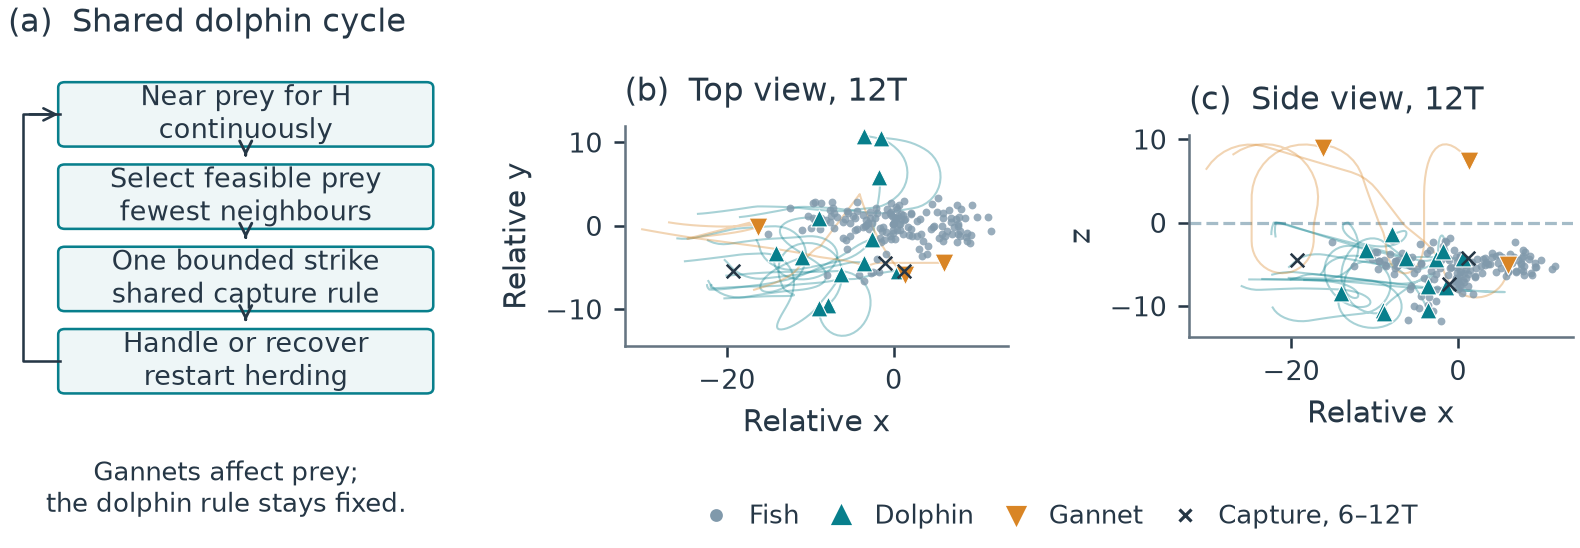

How a model feeding encounter works. (a) Dolphins maintain near-prey pressure for a minimum duration, pursue a feasible target and recover. Their rules do not change with bird presence. (b,c) Top and side views of one recorded encounter at 12 model-time units, with paths and captures from 6–12. This illustrates geometry, not proof of a compact bait ball.

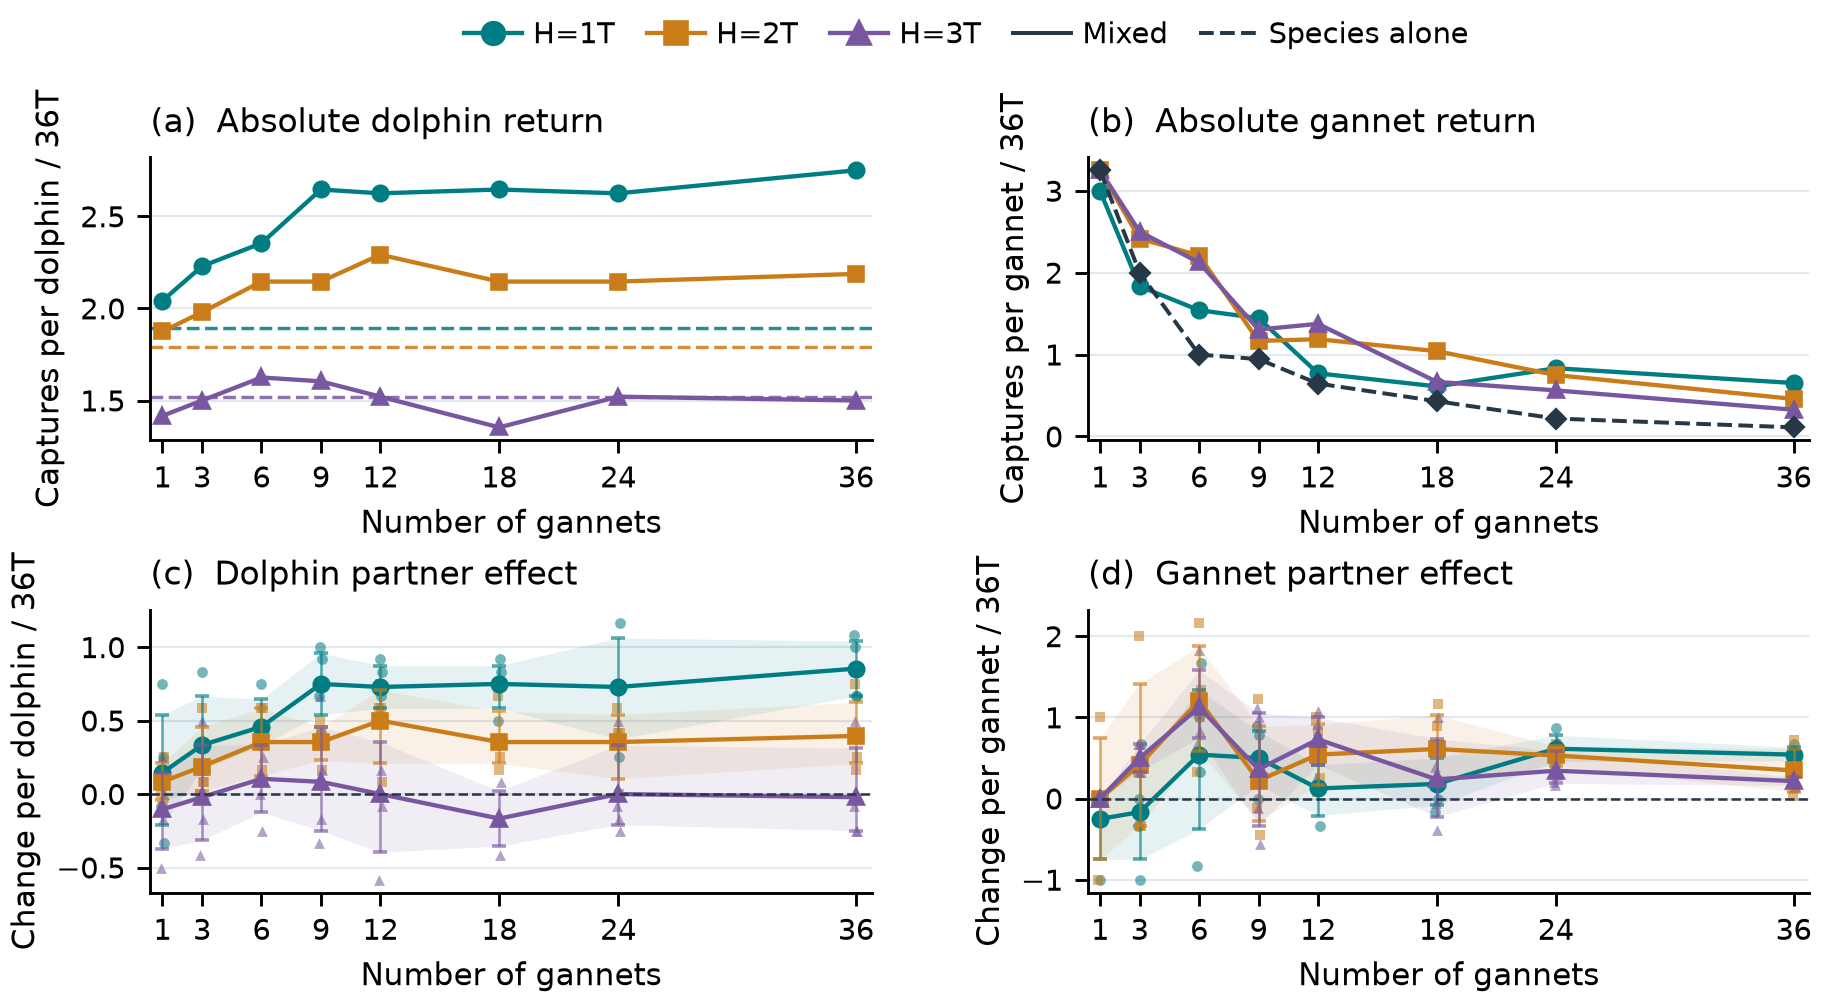

Absolute feeding returns and matched partner benefits through thirty-six gannets. (a,b) Captures per dolphin or gannet over the complete 36T encounter; dashed lines show matched single-species controls. Bird-only controls at each count are shared across H. (c,d) Changes relative to those controls: faint points show four paired school effects; bands and bars are exploratory pointwise 95% intervals for their means. Actual numeric bird-count spacing is retained.

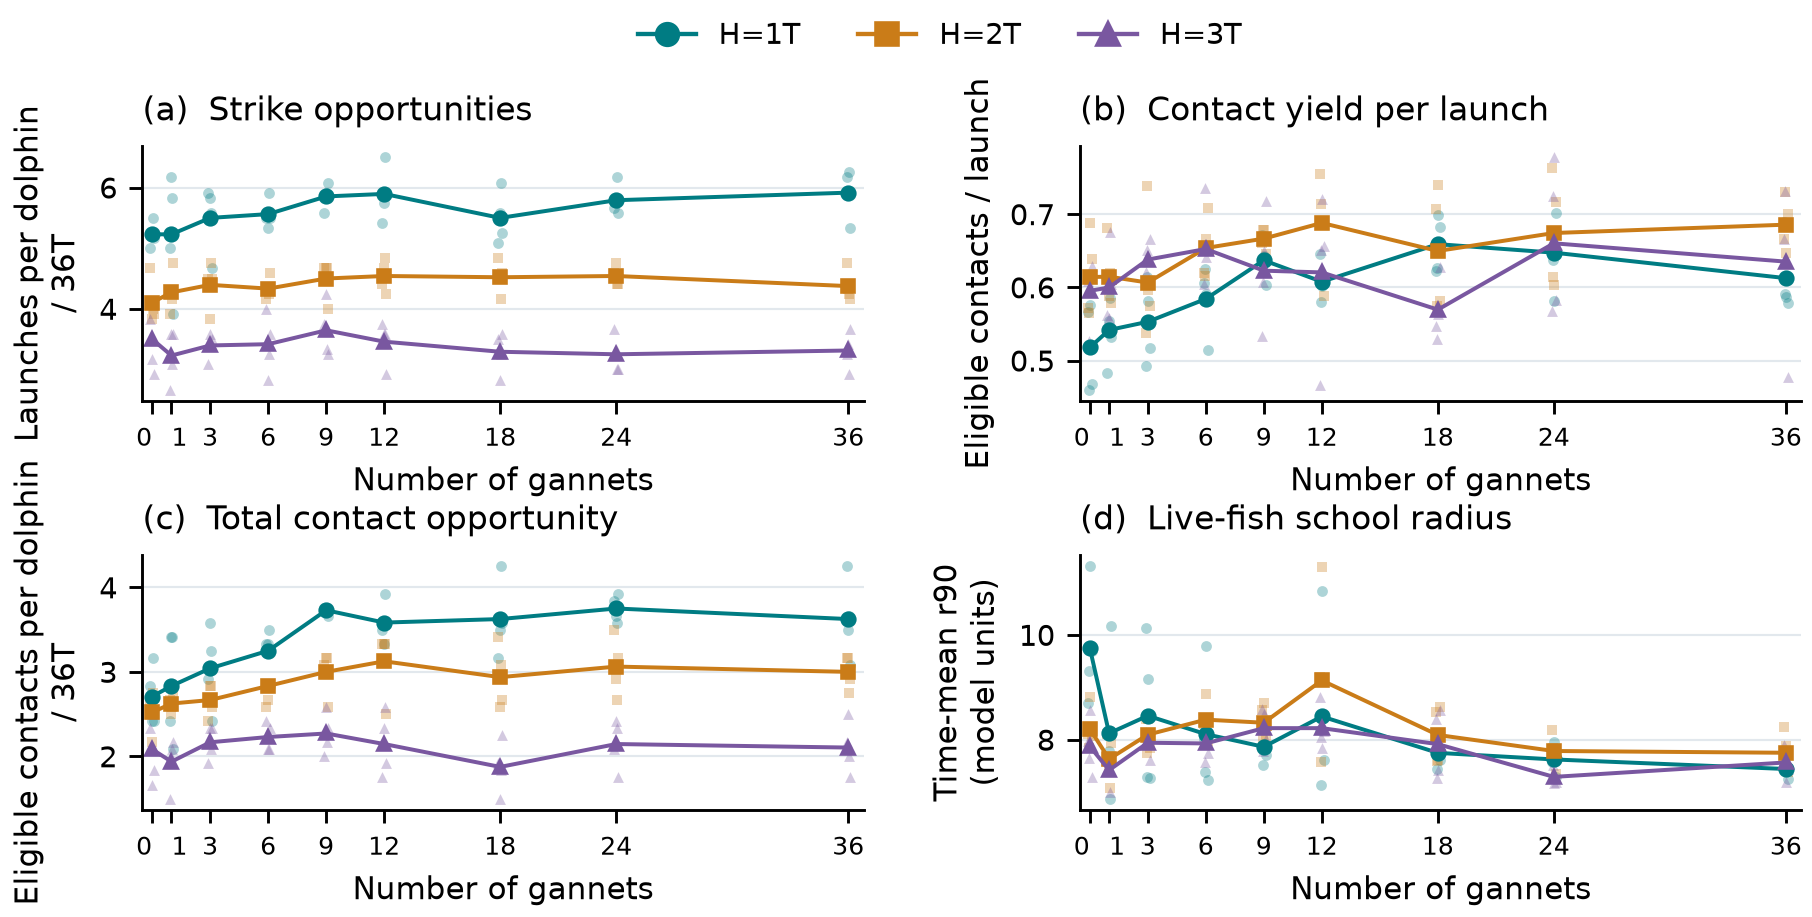

Herding duration changes strike opportunities and prey state. (a) Launches per dolphin; (b) eligible contacts per launch; (c) eligible contacts per dolphin; (d) live-fish r90. Counts cover 36T, including bird-free controls. Faint points show schools; lines join equal-school means except (b), which pools contacts/launches. r90 uses trapezoidal time averages over nonempty frames. School-state changes do not by themselves establish a feeding mechanism.

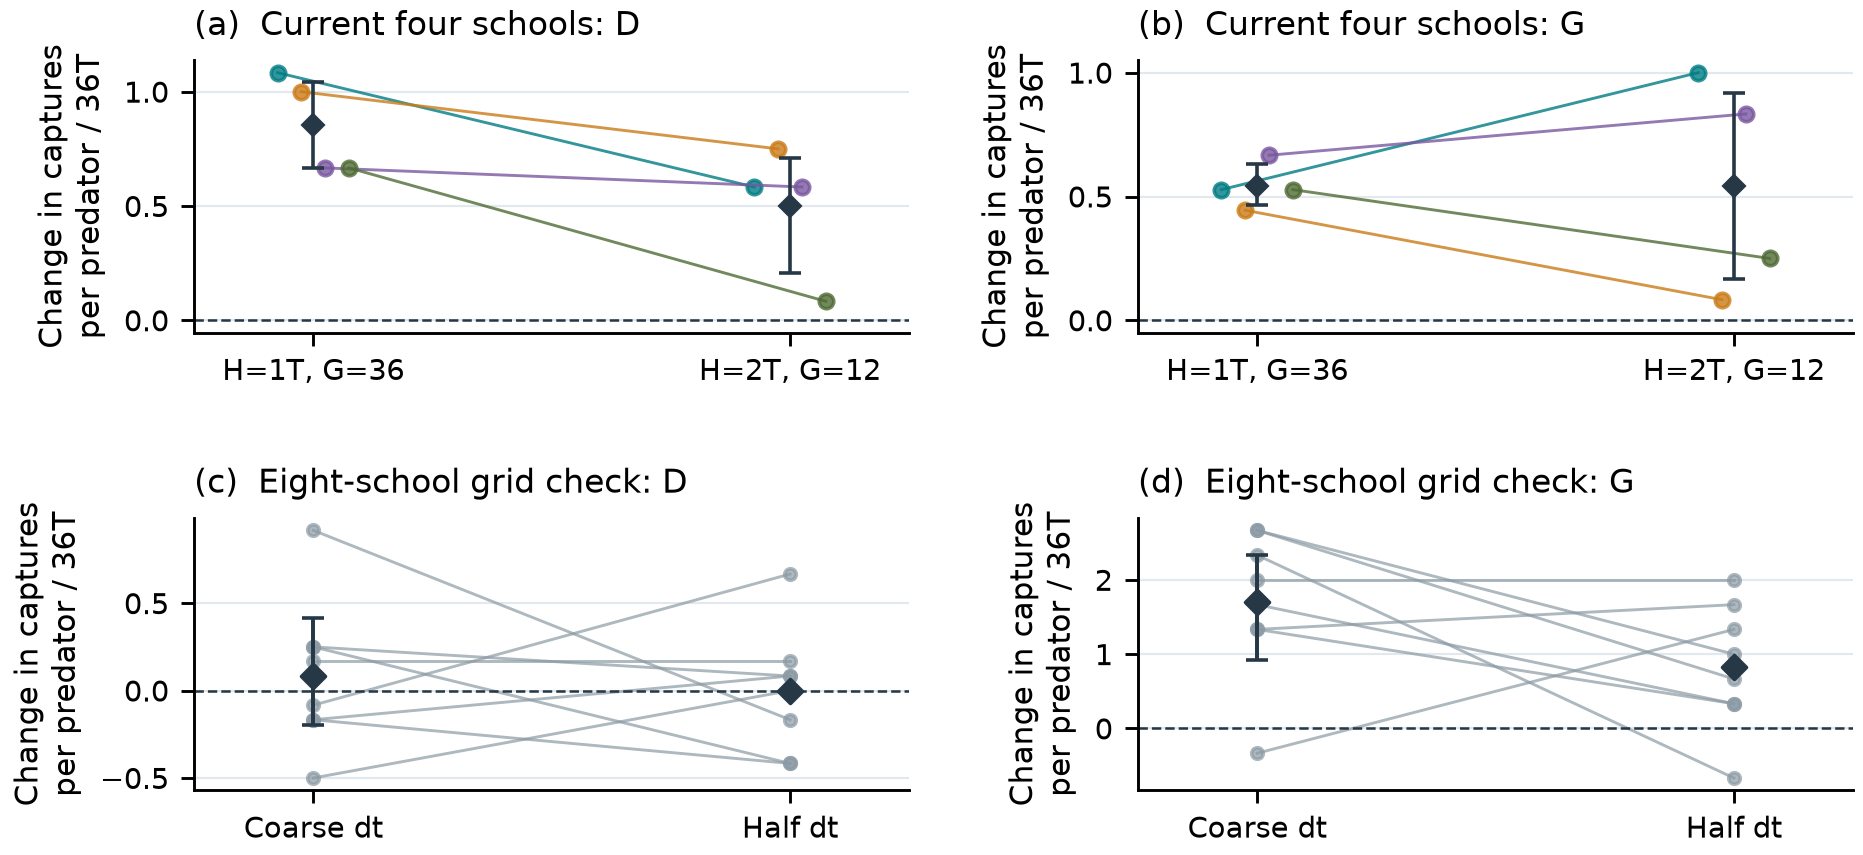

Selected mutual benefits and separate numerical sensitivity. (a,b) Four-school dolphin and bird effects at H = 1T with thirty-six birds and H = 2T with twelve birds, using matched controls and pointwise 95% intervals. (c,d) The distinct eight-school H = 2T, three-bird check across original and halved timesteps; only original means have 97.5% marginal intervals. Axes show changes per individual predator over 36T: twelve dolphins throughout, thirty-six/twelve birds above and three below. Thin lines connect the same school, diamonds mark means, and bars show the stated intervals. Schools and settings must not be pooled.

{
  "path": "/tmp/FishSim Upper Current Paper Candidate/paper_profiles/current_through36_2026-11-10/outputs/reproduced_figures",
  "figures": [
    "fig1_model",
    "fig2_returns",
    "fig3_opportunities",
    "fig4_sensitivity"
  ],
  "sources": 10,
  "all_sources_bundled": true,
  "figure1_scope": "Illustrative archived model image reused unchanged.",
  "r90_scope": "Saved per-school time means retained from the independent140-case diagnostic table, whose raw-trajectory frame check had zero maximum r90 error. This compact notebook does not recompute raw trajectories."
}


In [7]:
figures = analysis.render_figures()
captions = json.loads((ROOT / "captions.json").read_text()) if (ROOT / "captions.json").is_file() else {}
for name in figures["figures"]:
    display(Image(filename=str(Path(figures["path"]) / f"{name}.png")))
    if name in captions:
        display(Markdown(captions[name]))
print(json.dumps(figures, indent=2))

## Actual model execution is a different workflow

Read **`paper_profiles/current_through36_2026-11-10/MODEL_REPRODUCTION.txt`** and the exact documents in `paper_profiles/current_through36_2026-11-10/model_reproduction/` for the frozen code/configuration snapshot, optional execution route and native ABI requirements. This compact analysis package does not include a portable full-ensemble model launcher.

The archived `run_current_model.py` route executes the **eight-school H2/three-bird numerical study**, not the twenty-four-setting H×G map. The latter requires its frozen source-compatible checkpoint/configuration layout and preserved execution safeguards. The historical binary requires CPython 3.12, Linux x86-64, glibc 2.43 or newer and the documented C++/OpenMP runtime. The separate rebuilt Linux binary has bounded engineering checks, not a full feeding-ensemble validation. The public repository retains the prior v6 analysis and optional-model profile as versioned supplemental material. The existing optional root-notebook examples remain separately labelled and off by default; this standalone profile has no model cells.

The saved-output analysis above cannot start simulations. Separately validated short examples below remain disabled by default. The model environment is distinct from the analysis-kernel versions printed above.

## Completion checks

Input hashes are checked again after analysis. The verification receipt records the actual environment, deterministic comparisons, figure scope and zero model/bootstrap activity. The companion execution runner separately records completion in a fresh kernel, cell counts and elapsed wall time. A successful notebook execution is evidence for this saved-data path, not numerical convergence or biological validation.

In [8]:
verification = analysis.finish(inputs, mapped, numerical, departure, figures)
assert verification["native_model_imports"] == 0
assert verification["native_simulation_steps"] == 0
assert verification["new_bootstrap_draws"] == 0
print(json.dumps({k: verification[k] for k in [
    "status", "input_files_verified", "paired_effects_checked", "map_cases", "map_schools",
    "numerical_check_schools", "departure_runs", "seconds_in_kernel",
    "native_model_imports", "native_simulation_steps", "new_bootstrap_draws"]}, indent=2))

{
  "status": "passed",
  "input_files_verified": 53,
  "paired_effects_checked": 96,
  "map_cases": 140,
  "map_schools": 4,
  "numerical_check_schools": 8,
  "departure_runs": 48,
  "seconds_in_kernel": 2.516764802043326,
  "native_model_imports": 0,
  "native_simulation_steps": 0,
  "new_bootstrap_draws": 0
}


Earlier validated through18 examples only: `headline` = H1/G9 and `joint` = H2/G12. These do not execute H1/G36 or the full24-setting map.

## Reproduction scopes and optional new simulations

The default analysis above reconstructs the current paper from saved evidence. The optional `run_v6_example.py` frontend below executes a short matched D-only/DG pair from the v6 model: H1/G9 for 4T (`headline`) or H2/G12 for 2T (`joint`). Both are engineering demonstrations, not feeding-effect estimates or full-ensemble reruns.

Native execution is tested only on the documented Linux x86-64 CPython 3.12 environment. Docker/Windows/macOS/ARM invocation of this new interface is untested. See `V6_MODEL_SETUP.md` for setup and dated validation receipts. The unchanged `run_current_model.py` still covers its separate eight-school H2 coarse/fine scope; the historical runner and archive also remain unchanged.


Earlier validated through18 examples only: `headline` = H1/G9 and `joint` = H2/G12. These do not execute H1/G36 or the full24-setting map.

### Optional short model examples — execution disabled by default

The plan verifies the exact source/package and reads no new feeding outcomes. Choose `headline` or `joint`. The following cell runs native simulation only when `RUN_V6_MODEL = True`; it creates outputs outside the protected repository and then displays a position snapshot. The frozen plan's original preparation-status strings are superseded by the separate dated validation status.


In [9]:
# Plan only: no native import, construction or simulation steps.
import hashlib, json, subprocess, sys
addon = json.loads((PROJECT_ROOT/"ADDITIVE_HEADLINE_MODEL_MANIFEST_2026-11-09.json").read_text())
for relative, digest in addon["files"].items():
    assert hashlib.sha256((PROJECT_ROOT/relative).read_bytes()).hexdigest() == digest, relative
EXAMPLE_SETTING = "headline"  # "headline": H1/G9/4T; "joint": H2/G12/2T.
assert EXAMPLE_SETTING in ("headline", "joint")
plan_result = subprocess.run([
    sys.executable, "-B", "run_v6_example.py", "--plan",
    "--package-root", str(PROJECT_ROOT), "--setting", EXAMPLE_SETTING
], check=True, cwd=PROJECT_ROOT, capture_output=True, text=True)
print(plan_result.stdout)
print("Later validation: both binaries passed 108 exact starts and 20,000 bounded steps in total.")
print("Known Linux x86-64 / CPython 3.12 only; see V6_MODEL_SETUP.md and its dated receipts.")


{
  "schema": "fishsim_regime_example_plan_v3",
  "status": "plan_only",
  "scientific_scope": "V6 frozen 108-start model on four schools, coarse dt=.00125; bounded examples H1/G9 and H2/G12",
  "example_setting": "headline",
  "example_cases": [
    {
      "school_seed": 39061001,
      "policy": "H1_G0",
      "presence": "D",
      "capture_seed": 61001,
      "duration_T": 4.0
    },
    {
      "school_seed": 39061001,
      "policy": "H1_G9",
      "presence": "DG",
      "capture_seed": 61001,
      "duration_T": 4.0
    }
  ],
  "actual_zero_step_check_cases": 108,
  "planned_integration_native_steps": 6400,
  "native_imports": 0,
  "native_constructions": 0,
  "native_steps": 0,
  "unchanged_model": "Exact archived scientific Python/checkpoints/native C++ sources; derived builder/execution AST replaces historical operational gates only",
  "execution_status": "Not yet initialization/integration validated for this new regime harness",
  "interpretation": "Bounded 0.5T/2T/4T il

In [10]:
# Opt in only from the compatible model environment described in V6_MODEL_SETUP.md.
RUN_V6_MODEL = False

if RUN_V6_MODEL:
    from datetime import datetime, timezone
    import tempfile
    example_output = (Path(tempfile.gettempdir())/"fishsim_professor_examples"/
                      datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f"))
    subprocess.run([
        sys.executable, "-B", "run_v6_example.py", "--quick",
        "--package-root", str(PROJECT_ROOT), "--setting", EXAMPLE_SETTING,
        "--output", str(example_output)
    ], check=True, cwd=PROJECT_ROOT)
    from model_example_view import show_position_snapshot
    show_position_snapshot(example_output)
else:
    print("Native execution is disabled. All saved-result analysis remains available.")


Native execution is disabled. All saved-result analysis remains available.
